# DS605 Lab Assignment 8: Decision Trees and Support Vector Machines

**Dataset:** UCI Banknote Authentication (1,372 samples, 4 features, 2 classes)

This notebook follows the supplied assignment:
- **Part A:** Decision Tree from scratch
- **Part B:** Linear SVM from scratch
- **Part C:** Kernel SVM and nonlinear boundaries
- **Part D:** Final four-feature comparison

> Run the notebook from top to bottom. The banknote dataset is fetched from the UCI repository; an internet connection may be required the first time. Manual Decision Tree and Linear SVM implementations below use NumPy rather than scikit-learn.


## 0. Imports and reproducibility

In [1]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True


## 1. Load the UCI Banknote Authentication dataset

The dataset has four numeric features and a binary class label. For the 2D plots, this notebook uses **variance** and **skewness**; the final evaluation uses all four features.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
DATA_PATH = Path("data_banknote_authentication.txt")

if not DATA_PATH.exists():
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    except Exception as exc:
        raise RuntimeError(
            "Could not download the UCI dataset. Download "
            "'data_banknote_authentication.txt' from the UCI Banknote Authentication dataset "
            "and place it next to this notebook, then rerun this cell."
        ) from exc

columns = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv(DATA_PATH, header=None, names=columns)

print("Shape:", df.shape)
display(df.head())
display(df["class"].value_counts().rename("count").to_frame())


Shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,count
class,
0,762
1,610


## 2. Shared helpers: metrics and decision-boundary plots

In [3]:
def metric_row(y_true, y_pred, train_seconds=np.nan, predict_seconds=np.nan):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "train_seconds": train_seconds,
        "predict_seconds": predict_seconds,
    }


def plot_2d_boundary(model, X, y, title, feature_names=("variance", "skewness"), show_points=True):
    X = np.asarray(X)
    y = np.asarray(y)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = np.asarray(model.predict(grid)).reshape(xx.shape)

    plt.figure()
    plt.contourf(xx, yy, zz, alpha=0.22, levels=np.unique(zz).size + 1, cmap="coolwarm")
    if show_points:
        plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=22)
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.tight_layout()
    plt.show()


# Part A — Decision Tree from Scratch

We implement Gini impurity, entropy, candidate threshold search, recursive tree construction, and prediction without using scikit-learn for the manual model.

In [4]:
def gini_impurity(y):
    y = np.asarray(y)
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    y = np.asarray(y)
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return float(-np.sum(probabilities * np.log2(probabilities + 1e-12)))


def impurity(y, criterion):
    if criterion == "gini":
        return gini_impurity(y)
    if criterion == "entropy":
        return entropy(y)
    raise ValueError("criterion must be 'gini' or 'entropy'")


In [5]:
class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=4, min_samples_split=2, min_samples_leaf=1):
        if criterion not in {"gini", "entropy"}:
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.n_features_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X must be 2D and have the same number of rows as y")
        self.n_features_ = X.shape[1]
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        parent_impurity = impurity(y, self.criterion)
        best_gain, best_feature, best_threshold = 0.0, None, None

        for feature in range(n_features):
            values = np.unique(X[:, feature])
            if len(values) < 2:
                continue
            thresholds = (values[:-1] + values[1:]) / 2.0

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask
                n_left, n_right = left_mask.sum(), right_mask.sum()

                if min(n_left, n_right) < self.min_samples_leaf:
                    continue

                child_impurity = (
                    (n_left / n_samples) * impurity(y[left_mask], self.criterion)
                    + (n_right / n_samples) * impurity(y[right_mask], self.criterion)
                )
                gain = parent_impurity - child_impurity
                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, feature, threshold

        return best_feature, best_threshold, best_gain

    def _build_tree(self, X, y, depth):
        values, counts = np.unique(y, return_counts=True)
        prediction = values[np.argmax(counts)]
        node = {"prediction": prediction, "samples": len(y), "counts": dict(zip(values.tolist(), counts.tolist()))}

        pure = len(values) == 1
        depth_limit = self.max_depth is not None and depth >= self.max_depth
        too_small = len(y) < self.min_samples_split
        if pure or depth_limit or too_small:
            return node

        feature, threshold, gain = self._best_split(X, y)
        if feature is None or gain <= 0:
            return node

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask
        node.update({
            "feature": feature,
            "threshold": float(threshold),
            "gain": float(gain),
            "left": self._build_tree(X[left_mask], y[left_mask], depth + 1),
            "right": self._build_tree(X[right_mask], y[right_mask], depth + 1),
        })
        return node

    def _predict_one(self, row, node):
        while "feature" in node:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        return node["prediction"]

    def predict(self, X):
        if self.root is None:
            raise RuntimeError("Call fit before predict.")
        X = np.asarray(X, dtype=float)
        return np.asarray([self._predict_one(row, self.root) for row in X])

    def print_rules(self, feature_names, node=None, indent=""):
        if node is None:
            node = self.root
        if "feature" not in node:
            print(f"{indent}Predict class {node['prediction']} (samples={node['samples']})")
            return
        feature_name = feature_names[node["feature"]]
        print(f"{indent}if {feature_name} <= {node['threshold']:.5f}:")
        self.print_rules(feature_names, node["left"], indent + "  ")
        print(f"{indent}else:  # {feature_name} > {node['threshold']:.5f}")
        self.print_rules(feature_names, node["right"], indent + "  ")


## A1. Two-feature split and decision boundaries

Use a consistent train/test split for the two-feature demonstration. The model below is trained only on the training partition.

Manual tree: {'accuracy': 0.9212827988338192, 'precision': 0.874251497005988, 'recall': 0.9605263157894737, 'f1': 0.9153605015673981, 'train_seconds': 0.6124003999866545, 'predict_seconds': 0.0010380999883636832}
Scikit-learn tree: {'accuracy': 0.9212827988338192, 'precision': 0.874251497005988, 'recall': 0.9605263157894737, 'f1': 0.9153605015673981, 'train_seconds': 0.006004399969242513, 'predict_seconds': 0.0004795000422745943}


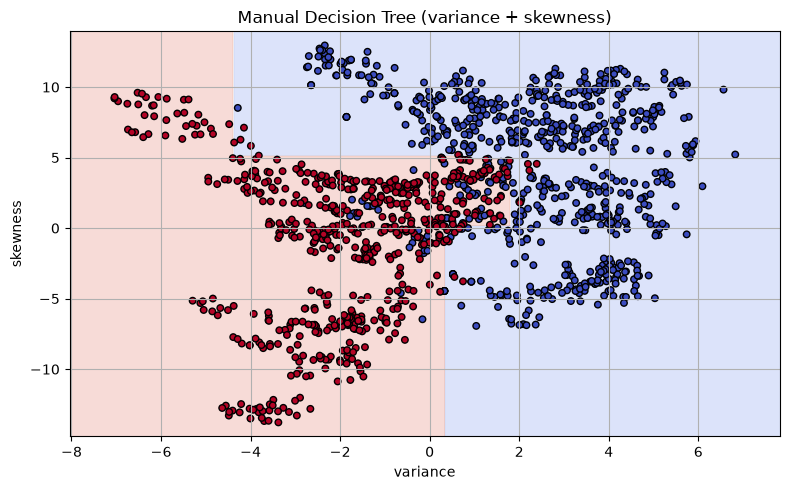

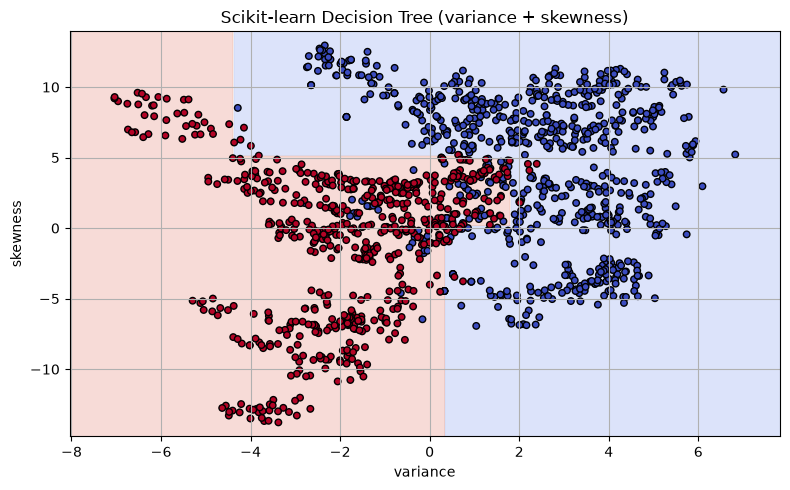

In [6]:
FEATURES_2D = ["variance", "skewness"]
X2 = df[FEATURES_2D].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

manual_tree_2d = ManualDecisionTree(criterion="gini", max_depth=4)
t0 = time.perf_counter()
manual_tree_2d.fit(X2_train, y2_train)
manual_tree_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
manual_tree_pred = manual_tree_2d.predict(X2_test)
manual_tree_predict_time = time.perf_counter() - t0

sk_tree_2d = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE)
t0 = time.perf_counter()
sk_tree_2d.fit(X2_train, y2_train)
sk_tree_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
sk_tree_pred = sk_tree_2d.predict(X2_test)
sk_tree_predict_time = time.perf_counter() - t0

print("Manual tree:", metric_row(y2_test, manual_tree_pred, manual_tree_train_time, manual_tree_predict_time))
print("Scikit-learn tree:", metric_row(y2_test, sk_tree_pred, sk_tree_train_time, sk_tree_predict_time))

plot_2d_boundary(manual_tree_2d, X2, y, "Manual Decision Tree (variance + skewness)")
plot_2d_boundary(sk_tree_2d, X2, y, "Scikit-learn Decision Tree (variance + skewness)")


## A2. Visualize the manual tree and its split rules

In [7]:
print("Manual tree split rules:")
manual_tree_2d.print_rules(FEATURES_2D)


Manual tree split rules:
if variance <= 0.76510:
  if skewness <= 5.16080:
    if variance <= 0.32016:
      if variance <= -0.45857:
        Predict class 1 (samples=328)
      else:  # variance > -0.45857
        Predict class 1 (samples=62)
    else:  # variance > 0.32016
      if skewness <= 0.98186:
        Predict class 0 (samples=27)
      else:  # skewness > 0.98186
        Predict class 1 (samples=19)
  else:  # skewness > 5.16080
    if variance <= -3.43110:
      if variance <= -4.38190:
        Predict class 1 (samples=25)
      else:  # variance > -4.38190
        Predict class 0 (samples=2)
    else:  # variance > -3.43110
      if skewness <= 5.36460:
        Predict class 0 (samples=2)
      else:  # skewness > 5.36460
        Predict class 0 (samples=90)
else:  # variance > 0.76510
  if variance <= 1.79070:
    if skewness <= 4.89795:
      if skewness <= 0.13760:
        Predict class 0 (samples=22)
      else:  # skewness > 0.13760
        Predict class 1 (samples=47

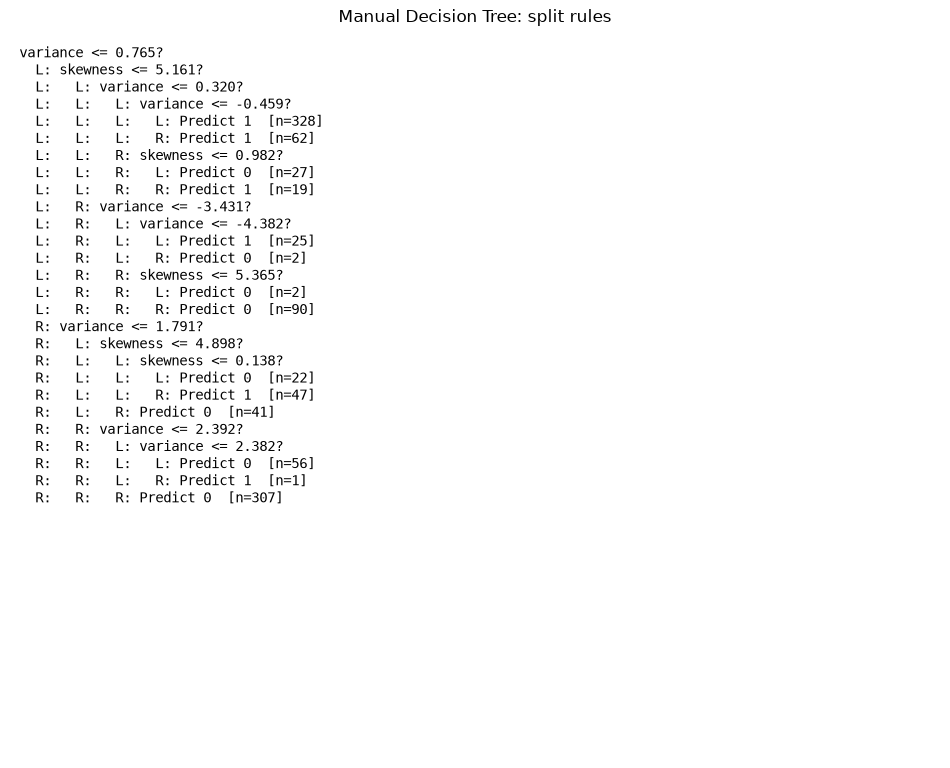

In [8]:
def draw_manual_tree(node, feature_names, ax=None):
    # Compact text-based visualization of the learned manual tree.
    lines = []
    def walk(n, prefix=""):
        if "feature" not in n:
            lines.append(f"{prefix}Predict {n['prediction']}  [n={n['samples']}]")
            return
        fname = feature_names[n["feature"]]
        lines.append(f"{prefix}{fname} <= {n['threshold']:.3f}?")
        walk(n["left"], prefix + "  L: ")
        walk(n["right"], prefix + "  R: ")
    walk(node)
    height = max(3, 0.35 * len(lines))
    fig, ax = plt.subplots(figsize=(12, height))
    ax.axis("off")
    ax.text(0.01, 0.98, "\n".join(lines), va="top", family="monospace", fontsize=10)
    ax.set_title("Manual Decision Tree: split rules")
    plt.show()

draw_manual_tree(manual_tree_2d.root, FEATURES_2D)


## A3. Explore criterion and maximum depth

This experiment compares held-out accuracy for Gini vs entropy and different depth limits. Scikit-learn is used only as the requested comparison model.

In [9]:
tree_experiment_rows = []
for criterion in ["gini", "entropy"]:
    for depth in [1, 2, 3, 4, 6, None]:
        manual = ManualDecisionTree(criterion=criterion, max_depth=depth).fit(X2_train, y2_train)
        pred = manual.predict(X2_test)
        sk = DecisionTreeClassifier(criterion=criterion, max_depth=depth, random_state=RANDOM_STATE).fit(X2_train, y2_train)
        sk_pred = sk.predict(X2_test)
        tree_experiment_rows.append({
            "criterion": criterion,
            "max_depth": str(depth),
            "manual_accuracy": accuracy_score(y2_test, pred),
            "sklearn_accuracy": accuracy_score(y2_test, sk_pred),
            "prediction_agreement": np.mean(pred == sk_pred),
        })

tree_experiments = pd.DataFrame(tree_experiment_rows)
display(tree_experiments)


,criterion,max_depth,manual_accuracy,sklearn_accuracy,prediction_agreement
0,gini,1,0.827988,0.827988,1.000000
1,gini,2,0.865889,0.865889,1.000000
2,gini,3,0.906706,0.906706,1.000000
3,gini,4,0.921283,0.921283,1.000000
4,gini,6,0.924198,0.930029,0.994169
5,gini,None,0.927114,0.918367,0.991254
6,entropy,1,0.827988,0.827988,1.000000
7,entropy,2,0.865889,0.865889,1.000000
8,entropy,3,0.897959,0.897959,1.000000
9,entropy,4,0.897959,0.897959,1.000000


# Part B — Linear SVM from Scratch

The manual model uses scaled features, labels encoded as -1 and +1, hinge loss, and subgradient descent. Scaling statistics are learned from the training data only.

In [10]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, n_iterations=3000):
        self.C = float(C)
        self.learning_rate = float(learning_rate)
        self.n_iterations = int(n_iterations)
        self.mean_ = None
        self.scale_ = None
        self.w_ = None
        self.b_ = 0.0
        self.classes_ = None
        self.loss_history_ = []

    def _scale_fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1.0
        return (X - self.mean_) / self.scale_

    def _scale_transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError("ManualLinearSVM requires exactly two classes.")
        y_signed = np.where(y == self.classes_[1], 1.0, -1.0)
        X_scaled = self._scale_fit(X)
        n_samples, n_features = X_scaled.shape
        self.w_ = np.zeros(n_features, dtype=float)
        self.b_ = 0.0
        self.loss_history_ = []

        for _ in range(self.n_iterations):
            margins = y_signed * (X_scaled @ self.w_ + self.b_)
            active = margins < 1.0
            # Objective: 0.5 * ||w||^2 + C * mean(max(0, 1 - y*f(x)))
            grad_w = self.w_.copy()
            grad_b = 0.0
            if np.any(active):
                grad_w -= self.C * np.mean(
                    (y_signed[active, None] * X_scaled[active]), axis=0
                ) * (active.sum() / n_samples)
                grad_b -= self.C * np.sum(y_signed[active]) / n_samples
            self.w_ -= self.learning_rate * grad_w
            self.b_ -= self.learning_rate * grad_b
            hinge = np.maximum(0.0, 1.0 - y_signed * (X_scaled @ self.w_ + self.b_))
            loss = 0.5 * np.dot(self.w_, self.w_) + self.C * np.mean(hinge)
            self.loss_history_.append(loss)
        return self

    def decision_function(self, X):
        X_scaled = self._scale_transform(np.asarray(X, dtype=float))
        return X_scaled @ self.w_ + self.b_

    def predict(self, X):
        signed = np.where(self.decision_function(X) >= 0, 1, -1)
        return np.where(signed == 1, self.classes_[1], self.classes_[0])


## B1. Train manual and Scikit-learn linear SVMs on the same two features

Manual linear SVM: {'accuracy': 0.880466472303207, 'precision': 0.9236641221374046, 'recall': 0.7960526315789473, 'f1': 0.8551236749116607, 'train_seconds': 0.5662037999136373, 'predict_seconds': 0.00018279999494552612}
Scikit-learn linear SVM: {'accuracy': 0.8892128279883382, 'precision': 0.8653846153846154, 'recall': 0.8881578947368421, 'f1': 0.8766233766233766, 'train_seconds': 0.12164700007997453, 'predict_seconds': 0.005056099966168404}


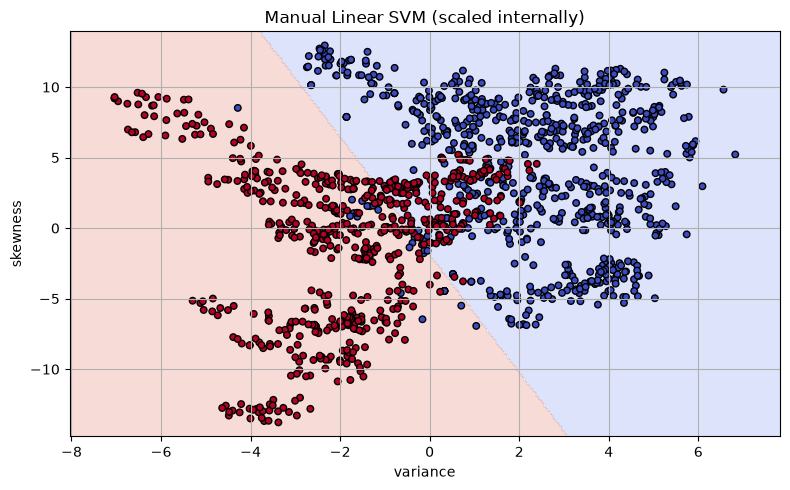

In [11]:
manual_svm_2d = ManualLinearSVM(C=1.0, learning_rate=0.001, n_iterations=4000)
t0 = time.perf_counter()
manual_svm_2d.fit(X2_train, y2_train)
manual_svm_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
manual_svm_pred = manual_svm_2d.predict(X2_test)
manual_svm_predict_time = time.perf_counter() - t0

# sklearn SVC uses a hinge-loss linear SVM optimization implementation.
sk_svm_2d = SVC(kernel="linear", C=1.0)
t0 = time.perf_counter()
sk_svm_2d.fit(
    (X2_train - X2_train.mean(axis=0)) / np.where(X2_train.std(axis=0) == 0, 1, X2_train.std(axis=0)),
    y2_train
)
sk_svm_train_time = time.perf_counter() - t0

X2_mean = X2_train.mean(axis=0)
X2_scale = X2_train.std(axis=0)
X2_scale[X2_scale == 0] = 1
X2_test_scaled = (X2_test - X2_mean) / X2_scale
t0 = time.perf_counter()
sk_svm_pred = sk_svm_2d.predict(X2_test_scaled)
sk_svm_predict_time = time.perf_counter() - t0

print("Manual linear SVM:", metric_row(y2_test, manual_svm_pred, manual_svm_train_time, manual_svm_predict_time))
print("Scikit-learn linear SVM:", metric_row(y2_test, sk_svm_pred, sk_svm_train_time, sk_svm_predict_time))
plot_2d_boundary(manual_svm_2d, X2, y, "Manual Linear SVM (scaled internally)")


## B2. Plot the manual SVM separating line, margins, and margin violations

The plotted contour uses the manual model's decision function. A sample is a margin violation when its signed margin is below 1; points inside the margin or on the wrong side are highlighted.

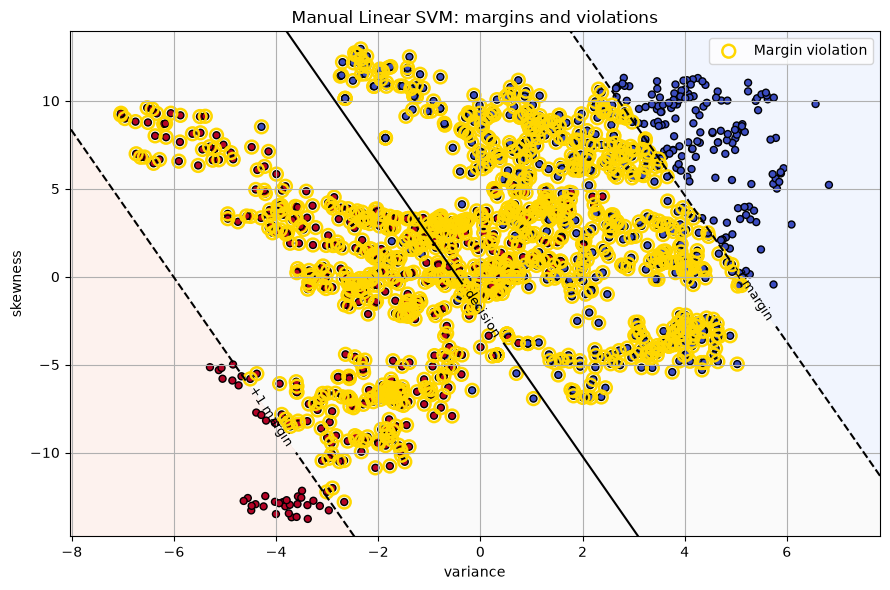

In [12]:
def plot_manual_svm_margins(model, X, y, title="Manual Linear SVM: margins and violations"):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    signed_y = np.where(y == model.classes_[1], 1, -1)
    margins = signed_y * model.decision_function(X)
    violations = margins < 1.0

    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, scores, levels=[-1e9, -1, 0, 1, 1e9],
                 alpha=0.12, cmap="coolwarm")
    contours = plt.contour(xx, yy, scores, levels=[-1, 0, 1], colors="black",
                            linestyles=["--", "-", "--"])
    plt.clabel(contours, inline=True, fontsize=9, fmt={-1: "-1 margin", 0: "decision", 1: "+1 margin"})
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    if violations.any():
        plt.scatter(X[violations, 0], X[violations, 1], s=85, facecolors="none",
                    edgecolors="gold", linewidths=1.8, label="Margin violation")
        plt.legend()
    plt.xlabel("variance")
    plt.ylabel("skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_manual_svm_margins(manual_svm_2d, X2, y)


## B3. Compare the Scikit-learn linear SVM decision boundary

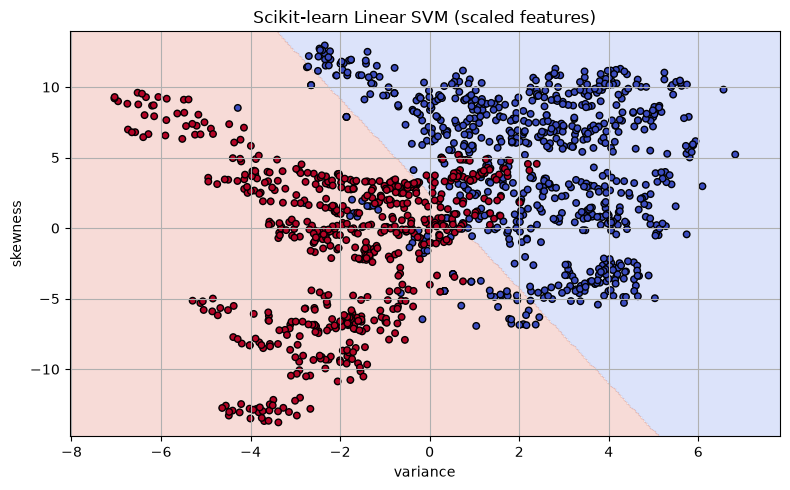

In [13]:
class ScaledSklearnSVM:
    def __init__(self, model, mean, scale):
        self.model = model
        self.mean = mean
        self.scale = scale
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.model.predict((X - self.mean) / self.scale)

sk_svm_boundary_model = ScaledSklearnSVM(sk_svm_2d, X2_mean, X2_scale)
plot_2d_boundary(sk_svm_boundary_model, X2, y, "Scikit-learn Linear SVM (scaled features)")


## B4. Explore regularization, learning rate, and iteration count

,C,learning_rate,iterations,accuracy,final_objective
0,0.1,0.0005,2000,0.892128,0.096879
1,0.1,0.0010,4000,0.871720,0.096049
2,0.1,0.0030,4000,0.650146,0.095083
3,1.0,0.0005,2000,0.892128,0.705347
4,1.0,0.0010,4000,0.880466,0.690182
5,1.0,0.0030,4000,0.874636,0.689815
6,10.0,0.0005,2000,0.889213,4.080156
7,10.0,0.0010,4000,0.892128,4.079419
8,10.0,0.0030,4000,0.892128,4.079419


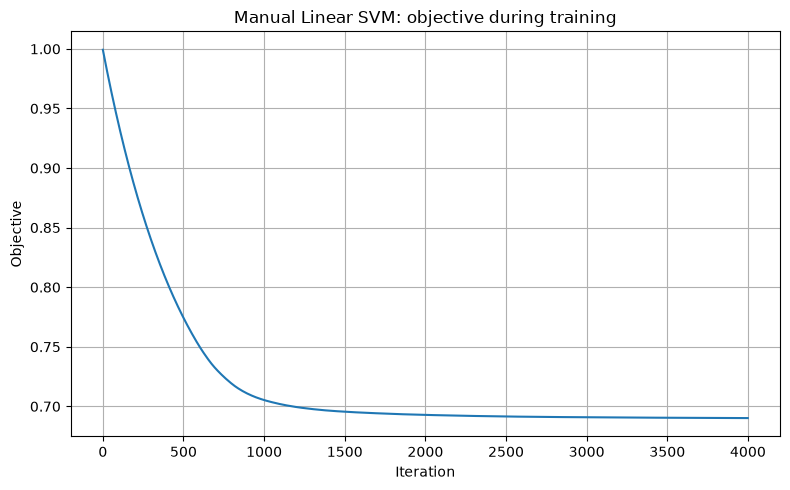

In [14]:
svm_experiment_rows = []
for C in [0.1, 1.0, 10.0]:
    for learning_rate, iterations in [(0.0005, 2000), (0.001, 4000), (0.003, 4000)]:
        model = ManualLinearSVM(C=C, learning_rate=learning_rate, n_iterations=iterations)
        model.fit(X2_train, y2_train)
        pred = model.predict(X2_test)
        svm_experiment_rows.append({
            "C": C,
            "learning_rate": learning_rate,
            "iterations": iterations,
            "accuracy": accuracy_score(y2_test, pred),
            "final_objective": model.loss_history_[-1],
        })

svm_experiments = pd.DataFrame(svm_experiment_rows)
display(svm_experiments)
plt.figure()
plt.plot(manual_svm_2d.loss_history_)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("Manual Linear SVM: objective during training")
plt.tight_layout()
plt.show()


# Part C — Kernel SVM and Nonlinear Boundaries

Generate a nonlinear two-dimensional dataset and compare linear, polynomial, and RBF SVM kernels.

,accuracy,precision,recall,f1,train_seconds,predict_seconds
kernel,,,,,,
linear,0.866667,0.848101,0.893333,0.870130,0.005163,0.001069
poly,0.906667,0.850575,0.986667,0.913580,0.003835,0.000844
rbf,0.940000,0.912500,0.973333,0.941935,0.003741,0.002412


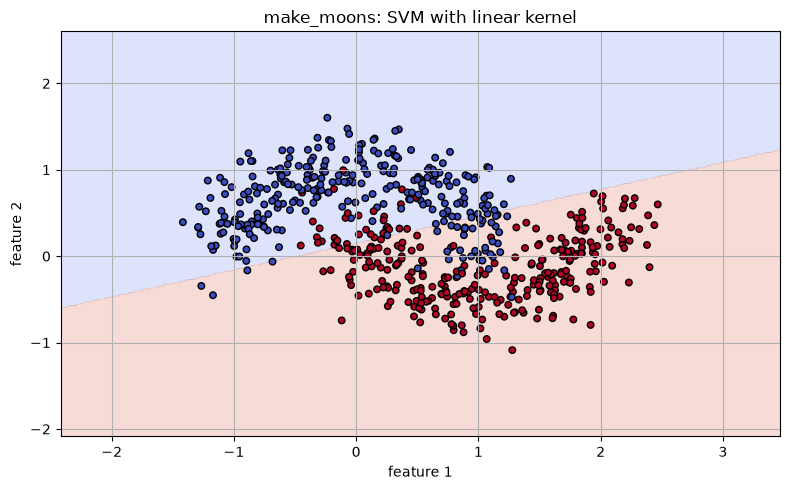

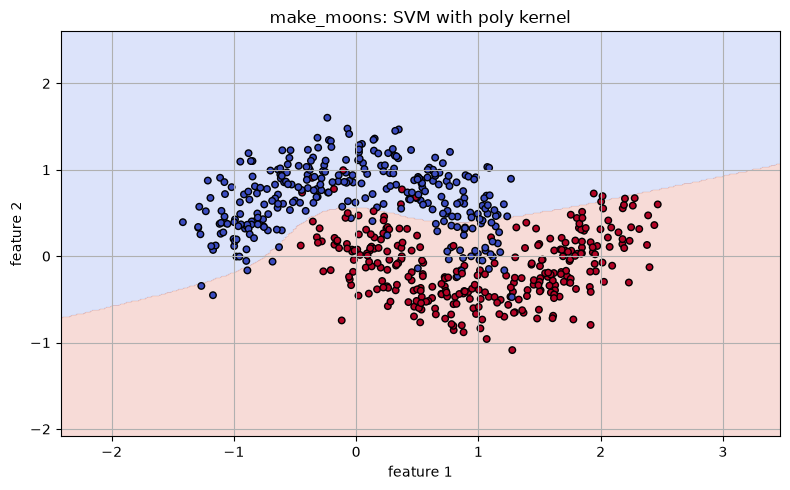

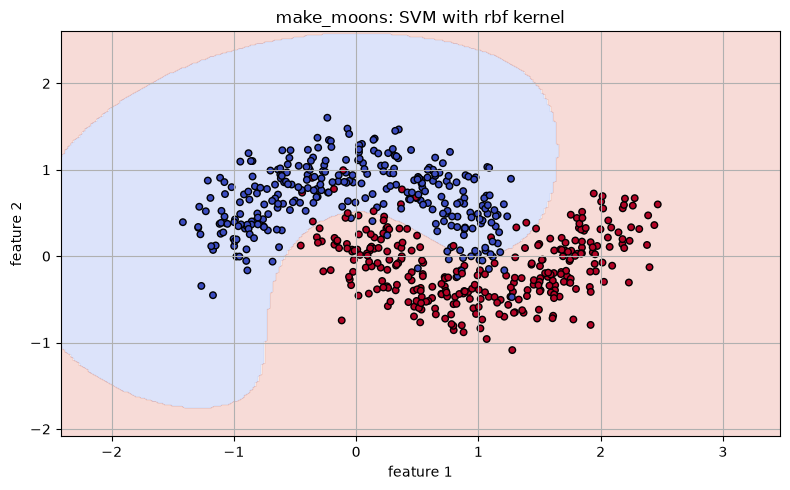

In [15]:
X_moons, y_moons = make_moons(n_samples=600, noise=0.22, random_state=RANDOM_STATE)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.25, random_state=RANDOM_STATE, stratify=y_moons
)

kernel_models = {}
kernel_rows = []
for kernel in ["linear", "poly", "rbf"]:
    model = SVC(kernel=kernel, C=1.0, gamma="scale", degree=3)
    t0 = time.perf_counter()
    model.fit(X_moons_train, y_moons_train)
    train_seconds = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(X_moons_test)
    predict_seconds = time.perf_counter() - t0
    kernel_models[kernel] = model
    row = metric_row(y_moons_test, pred, train_seconds, predict_seconds)
    row["kernel"] = kernel
    kernel_rows.append(row)

display(pd.DataFrame(kernel_rows).set_index("kernel"))
for kernel, model in kernel_models.items():
    plot_2d_boundary(model, X_moons, y_moons, f"make_moons: SVM with {kernel} kernel",
                     feature_names=("feature 1", "feature 2"))


**Discussion prompt:** A linear kernel creates a straight separating boundary. Polynomial and RBF kernels can represent curved boundaries, which may fit nonlinear patterns better. A more flexible boundary can also overfit, so use held-out evaluation rather than judging only by the plot.

# Part D — Final Comparison Using All Four Features

Use one consistent train-test split for all models. Manual Decision Tree and Manual Linear SVM are implemented above; scikit-learn models are included as comparisons. The RBF SVM uses all four original features with scaling learned from the training set.

In [16]:
X4 = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(dtype=float)
y4 = df["class"].to_numpy(dtype=int)
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.25, random_state=RANDOM_STATE, stratify=y4
)

final_rows = []

def evaluate_model(name, model, X_train, y_train, X_test, y_test, fit_fn=None, predict_fn=None):
    t0 = time.perf_counter()
    if fit_fn is None:
        model.fit(X_train, y_train)
    else:
        fit_fn(model, X_train, y_train)
    train_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    if predict_fn is None:
        pred = model.predict(X_test)
    else:
        pred = predict_fn(model, X_test)
    predict_seconds = time.perf_counter() - t0

    row = metric_row(y_test, pred, train_seconds, predict_seconds)
    row["model"] = name
    final_rows.append(row)
    return pred

# Manual Decision Tree, all four features
manual_tree_4d = ManualDecisionTree(criterion="gini", max_depth=5)
evaluate_model("Manual Decision Tree", manual_tree_4d, X4_train, y4_train, X4_test, y4_test)

# Scikit-learn Decision Tree
sk_tree_4d = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=RANDOM_STATE)
evaluate_model("Scikit-learn Decision Tree", sk_tree_4d, X4_train, y4_train, X4_test, y4_test)

# Manual linear SVM scales using training-set statistics inside fit()
manual_svm_4d = ManualLinearSVM(C=1.0, learning_rate=0.001, n_iterations=5000)
evaluate_model("Manual Linear SVM", manual_svm_4d, X4_train, y4_train, X4_test, y4_test)

# Scikit-learn linear SVM, explicit train-only standardization
mean4 = X4_train.mean(axis=0)
scale4 = X4_train.std(axis=0)
scale4[scale4 == 0] = 1
X4_train_scaled = (X4_train - mean4) / scale4
X4_test_scaled = (X4_test - mean4) / scale4

sk_svm_4d = SVC(kernel="linear", C=1.0)
evaluate_model("Scikit-learn Linear SVM", sk_svm_4d, X4_train_scaled, y4_train, X4_test_scaled, y4_test)

# RBF SVM with all four features, scaled using training data only
rbf_svm_4d = SVC(kernel="rbf", C=1.0, gamma="scale")
evaluate_model("Scikit-learn RBF SVM", rbf_svm_4d, X4_train_scaled, y4_train, X4_test_scaled, y4_test)

final_results = pd.DataFrame(final_rows).set_index("model")
display(final_results.sort_values("f1", ascending=False))


,accuracy,precision,recall,f1,train_seconds,predict_seconds
model,,,,,,
Scikit-learn RBF SVM,1.000000,1.000000,1.000000,1.000000,0.007302,0.002717
Manual Decision Tree,0.985423,0.974194,0.993421,0.983713,1.386075,0.000692
Scikit-learn Decision Tree,0.985423,0.974194,0.993421,0.983713,0.002939,0.000270
Scikit-learn Linear SVM,0.976676,0.950000,1.000000,0.974359,0.008935,0.000802
Manual Linear SVM,0.889213,0.938462,0.802632,0.865248,0.875067,0.000050


## D1. Confusion matrices and classification reports

In [17]:
final_models_and_predictions = {
    "Manual Decision Tree": (manual_tree_4d, manual_tree_4d.predict(X4_test)),
    "Scikit-learn Decision Tree": (sk_tree_4d, sk_tree_4d.predict(X4_test)),
    "Manual Linear SVM": (manual_svm_4d, manual_svm_4d.predict(X4_test)),
    "Scikit-learn Linear SVM": (sk_svm_4d, sk_svm_4d.predict(X4_test_scaled)),
    "Scikit-learn RBF SVM": (rbf_svm_4d, rbf_svm_4d.predict(X4_test_scaled)),
}

for name, (_, pred) in final_models_and_predictions.items():
    print("\n" + "=" * 72)
    print(name)
    print("Confusion matrix:\n", confusion_matrix(y4_test, pred))
    print(classification_report(y4_test, pred, zero_division=0))



Manual Decision Tree
Confusion matrix:
 [[187   4]
 [  1 151]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       191
           1       0.97      0.99      0.98       152

    accuracy                           0.99       343
   macro avg       0.98      0.99      0.99       343
weighted avg       0.99      0.99      0.99       343


Scikit-learn Decision Tree
Confusion matrix:
 [[187   4]
 [  1 151]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       191
           1       0.97      0.99      0.98       152

    accuracy                           0.99       343
   macro avg       0.98      0.99      0.99       343
weighted avg       0.99      0.99      0.99       343


Manual Linear SVM
Confusion matrix:
 [[183   8]
 [ 30 122]]
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       191
           1       0.94      0.80      0.8

## D2. Final observations

Complete these notes after running the notebook and reviewing the output.

1. **Accuracy, precision, recall, and F1:** Which model performs best on the held-out test set? Are any metrics notably different?
2. **Training and prediction time:** Which models are fastest in this run? Timing varies with hardware and execution environment.
3. **Interpretability:** A decision tree can be inspected as human-readable split rules; an SVM is generally less directly interpretable.
4. **Scaling:** SVMs are sensitive to feature scale, so scale using training-set statistics. Decision trees generally do not require feature scaling.
5. **Overfitting and complexity:** Deep trees and flexible kernels can fit training patterns closely. Compare held-out results and vary depth / `C` instead of relying only on training accuracy.
6. **Manual vs. library implementation:** Differences can result from optimization procedures, stopping rules, and implementation details.

